## **Load Libraries**

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.listdir()

['app2.py',
 'input',
 'output',
 'Remove DC component',
 'Task.ipynb',
 'Test Cases',
 'Test_files']

## **Read Data**

In [19]:
folder_path = "input"

In [20]:
def read_signal_folder(folder_path):
    signals = {}

    for file_name in os.listdir(folder_path):

        if file_name.endswith(".txt"):
            file_path = os.path.join(folder_path, file_name)
            indices = []
            samples = []

            amplitudes = []
            phases = []

            with open(file_path, "r") as file:
                file_type =  int(file.readline())
                file.readline()

                if file_type == 0:
                  num_samples = int(file.readline().strip())

                  for i in range(num_samples):
                        line = file.readline().strip()
                        parts = line.split()

                        index = int(parts[0])
                        sample = float(parts[1])

                        indices.append(index)
                        samples.append(sample)

                elif file_type == 1:
                    num_samples = int(file.readline().strip())

                    for i in range(num_samples):
                        line = file.readline().strip()
                        parts = line.split()

                        parts[0] = parts[0].strip('f')
                        parts[1] = parts[1].strip('f')

                        amplitude = float(parts[0])
                        phase = float(parts[1])

                        amplitudes.append(amplitude)
                        phases.append(phase)


            signal_name = os.path.splitext(file_name)[0]

            if file_type == 0:
                signals[signal_name] = {
                    "indices": indices,
                    "samples": samples
                }
            else: 
                signals[signal_name]={
                    "amplitudes" : amplitudes,
                    "phases": phases
                }

    return signals


In [21]:

def read_files(folder_path):
    math_path = os.path.join(folder_path, "operation_input")
    quant_path = os.path.join(folder_path, "quant_input")
    fourier_path = os.path.join(folder_path, "task3")

    signals = read_signal_folder(math_path)
    quant_signals = read_signal_folder(quant_path)
    fourier_signals = read_signal_folder(fourier_path)

    return signals, quant_signals , fourier_signals

In [22]:
signals, quant_signals, fourier_signals = read_files(folder_path)

In [23]:
print (fourier_signals.keys())

dict_keys(['DC_component_input', 'input_Signal_DFT', 'Input_Signal_IDFT_A,Phase'])


In [24]:
print(quant_signals.keys())

dict_keys(['Quan1_input', 'Quan2_input'])


## **Display Functions**

### Display continuous 

In [25]:
def dis_cont(signal_name, signals):
    indices = signals[signal_name]["indices"]
    samples = signals[signal_name]["samples"]

    plt.plot(indices, samples)
    plt.xlabel("Index")
    plt.ylabel("Amplitude")
    plt.title(f"Signal: {signal_name}")
    plt.show()
    return

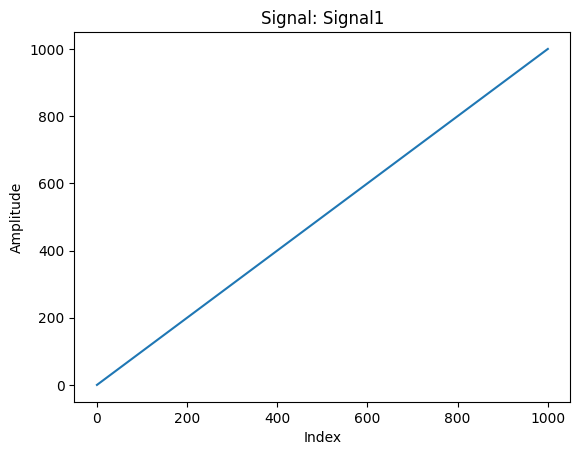

In [26]:
dis_cont("Signal1", signals)

### Display Discrete

In [27]:
def dis_dicrete(signal_name , signals):

    indices = signals[signal_name]["indices"]
    samples = signals[signal_name]["samples"]

    plt.figure(figsize=(10, 6))
    plt.stem(indices, samples)

    plt.xlabel("Index")
    plt.ylabel("Signlal Value")
    plt.title(f"Signal: {signal_name}")
    plt.show()
    return


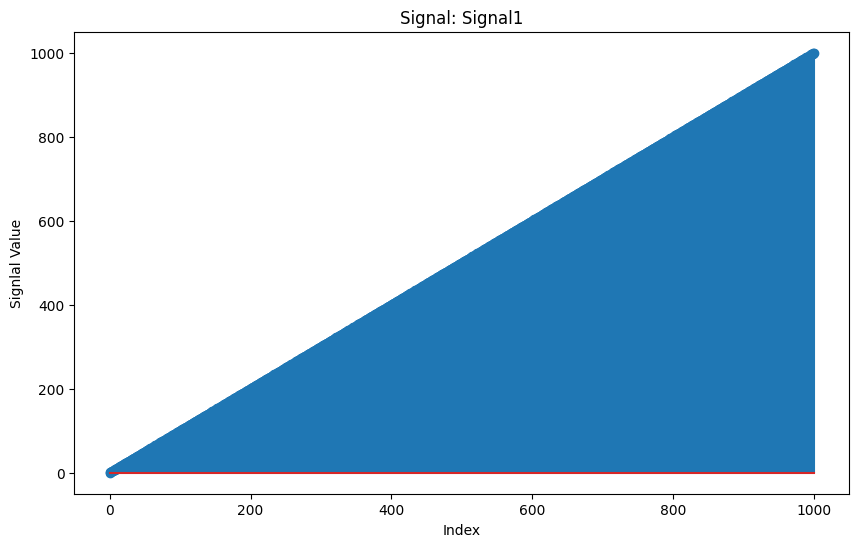

In [28]:
dis_dicrete("Signal1", signals)

---


## **Math operations**

### Addition Function

In [29]:
def add_signals(signals , signal_names):

    result_indices = signals[signal_names[0]]['indices'].copy()
    result_samples = [0] * len(result_indices)

    for name in signal_names: 
        samples = signals[name]['samples']

        for i in range(len(result_indices)):
            result_samples[i] += samples[i]

    return result_indices , result_samples

In [30]:
indices, samples = add_signals(
    signals,
    ['Signal1', 'Signal3']
)

In [31]:
new_signal = {
    "indices": indices,
    "samples": samples
}
signals["Signal1_new"] = new_signal

### Multiplication Function

In [32]:
def mul_const(const, signals, signal_name):

    indices = signals[signal_name]['indices'].copy()
    samples = signals[signal_name]['samples'].copy()

    samples = [sample * const for sample in samples]

    return indices, samples

In [33]:
new_signal = mul_const(-1, signals, "Signal1")
signals["Signal1_new"] = new_signal

---
## **Task2**

### Squaring Function

In [34]:
def squaring(signals, signal_name):

    indices = signals[signal_name]['indices'].copy()
    samples = signals[signal_name]['samples'].copy()

    samples = [sample * sample for sample in samples]

    return indices, samples

In [35]:
indices, samples = squaring(
    signals,
    'Signal1'
)

print(samples)

[0.0, 1.0, 4.0, 9.0, 16.0, 25.0, 36.0, 49.0, 64.0, 81.0, 100.0, 121.0, 144.0, 169.0, 196.0, 225.0, 256.0, 289.0, 324.0, 361.0, 400.0, 441.0, 484.0, 529.0, 576.0, 625.0, 676.0, 729.0, 784.0, 841.0, 900.0, 961.0, 1024.0, 1089.0, 1156.0, 1225.0, 1296.0, 1369.0, 1444.0, 1521.0, 1600.0, 1681.0, 1764.0, 1849.0, 1936.0, 2025.0, 2116.0, 2209.0, 2304.0, 2401.0, 2500.0, 2601.0, 2704.0, 2809.0, 2916.0, 3025.0, 3136.0, 3249.0, 3364.0, 3481.0, 3600.0, 3721.0, 3844.0, 3969.0, 4096.0, 4225.0, 4356.0, 4489.0, 4624.0, 4761.0, 4900.0, 5041.0, 5184.0, 5329.0, 5476.0, 5625.0, 5776.0, 5929.0, 6084.0, 6241.0, 6400.0, 6561.0, 6724.0, 6889.0, 7056.0, 7225.0, 7396.0, 7569.0, 7744.0, 7921.0, 8100.0, 8281.0, 8464.0, 8649.0, 8836.0, 9025.0, 9216.0, 9409.0, 9604.0, 9801.0, 10000.0, 10201.0, 10404.0, 10609.0, 10816.0, 11025.0, 11236.0, 11449.0, 11664.0, 11881.0, 12100.0, 12321.0, 12544.0, 12769.0, 12996.0, 13225.0, 13456.0, 13689.0, 13924.0, 14161.0, 14400.0, 14641.0, 14884.0, 15129.0, 15376.0, 15625.0, 15876.0, 16

### Accumulation Function

In [36]:
def accum(singnals , signal_name):

    indices = singnals[signal_name]['indices'].copy()
    new_samples = []
    samples = singnals[signal_name]['samples'].copy()

    size = len(indices)

    for i in range(size): 

        if i == 0:
            new_samples.append(samples[i])
        else: 
            new_samples.append(new_samples[i-1] + samples[i])

    return indices , new_samples



In [37]:
indices, samples = accum(
    signals,
    'Signal1'
)

print(samples)

[0.0, 1.0, 3.0, 6.0, 10.0, 15.0, 21.0, 28.0, 36.0, 45.0, 55.0, 66.0, 78.0, 91.0, 105.0, 120.0, 136.0, 153.0, 171.0, 190.0, 210.0, 231.0, 253.0, 276.0, 300.0, 325.0, 351.0, 378.0, 406.0, 435.0, 465.0, 496.0, 528.0, 561.0, 595.0, 630.0, 666.0, 703.0, 741.0, 780.0, 820.0, 861.0, 903.0, 946.0, 990.0, 1035.0, 1081.0, 1128.0, 1176.0, 1225.0, 1275.0, 1326.0, 1378.0, 1431.0, 1485.0, 1540.0, 1596.0, 1653.0, 1711.0, 1770.0, 1830.0, 1891.0, 1953.0, 2016.0, 2080.0, 2145.0, 2211.0, 2278.0, 2346.0, 2415.0, 2485.0, 2556.0, 2628.0, 2701.0, 2775.0, 2850.0, 2926.0, 3003.0, 3081.0, 3160.0, 3240.0, 3321.0, 3403.0, 3486.0, 3570.0, 3655.0, 3741.0, 3828.0, 3916.0, 4005.0, 4095.0, 4186.0, 4278.0, 4371.0, 4465.0, 4560.0, 4656.0, 4753.0, 4851.0, 4950.0, 5050.0, 5151.0, 5253.0, 5356.0, 5460.0, 5565.0, 5671.0, 5778.0, 5886.0, 5995.0, 6105.0, 6216.0, 6328.0, 6441.0, 6555.0, 6670.0, 6786.0, 6903.0, 7021.0, 7140.0, 7260.0, 7381.0, 7503.0, 7626.0, 7750.0, 7875.0, 8001.0, 8128.0, 8256.0, 8385.0, 8515.0, 8646.0, 8778.0

### Subtraction

In [38]:
def sub_signals(signals , signal_names):
     
     result_indices = signals[signal_names[0]]['indices'].copy()
     result_samples = signals[signal_names[0]]['samples'].copy()
    
     for name in signal_names[1:]: 
            samples = signals[name]['samples']
    
            for i in range(len(result_indices)):
                result_samples[i] = np.abs(result_samples[i] - samples[i])
    
     return result_indices , result_samples
    

### Normalization

In [39]:
def normalization(type , signals , sig_name):

    indices = signals[sig_name]['indices'].copy()
    samples = signals[sig_name]['samples'].copy()

    new_samples = [] 

    size = len(samples)
    x_min = min(samples)
    x_max = max(samples)

    if x_min == x_max: 
        print("Error can't preform normalization")
        return 

    elif type == "zero_to_one":

        for i in range(size):
            new_samples.append((samples[i] - x_min) / (x_max - x_min))

    elif type == "minus_one_to_one":

        for i in range(size):
            new_val = 2 * (samples[i] - x_min) / (x_max - x_min) - 1
            new_samples.append(new_val)

    return indices , new_samples


----


## **Perform Quantization**

In [40]:
def calc_quant(num_type ,num, signals , sing_name):

    #Calculate number of levels 
    if num_type == "bits":
        num_levels = 2 ** num
    elif num_type == "levels":
        num_levels = num

    samples = signals[sing_name]['samples'].copy()

    x_min = min(samples)
    x_max = max(samples)

    delta = (x_max - x_min) / num_levels

    #create quantization ranges
    ranges = []

    for i in range(num_levels):
        lower = x_min + i * delta

        if i == num_levels - 1:
            upper = x_max
        else:
            upper = x_min + (i + 1) * delta

        mid_point = (lower + upper) / 2

        r = {
          "lower": lower,
          "upper": upper,
          "mid_point": mid_point,
          "level": i
        }

        ranges.append(r)


    # Quantize sample and save their level indices
    quantized_samples = []
    level_indices = []

    for sample in samples: 
        for i, r in enumerate(ranges):

            if (r == (ranges[-1])):
                if r["lower"] <= sample <= r["upper"]:
                        quantized_samples.append(r["mid_point"])
                        level_indices.append(r["level"])
                        break

            else:
                if r["lower"] <= sample < r["upper"]:
                  quantized_samples.append(r["mid_point"])
                  level_indices.append(r["level"])
                  break

    return quantized_samples, ranges, level_indices


### 

In [41]:
def encoded_sig(num_type, num, signals, sig_name):

    if num_type == "levels":
        bits = int(np.ceil(np.log2(num)))
    elif num_type == "bits":
        bits = int(num)
    else:
        raise ValueError("num_type must be 'levels' or 'bits'")

    quantized_samples, ranges, level_indices = calc_quant(
        num_type, num, signals, sig_name
    )

    encoded_samples = []

    for level_index in level_indices:
        encoded_samples.append(format(level_index, f"0{bits}b"))

    return encoded_samples


In [42]:
#Calculate the quantization error 

def calc_quant_error(quat_signal , signals , original_signal):

    original_samples = signals[original_signal]['samples'].copy()
    quant_samples = signals[quat_signal]['samples'].copy()

    errors = 0
    error_samples = []

    for i in range(len(original_samples)):
        error = (quant_samples[i] - original_samples[i]) 
        error_samples.append(error)

        errors += error **2

    total_error = errors / len(original_samples)

    return total_error , error_samples

  

In [43]:

# Show available quantization signals
print("Available quantization signals:")
print(list(quant_signals.keys()))

# Choose the first signal from the quantization folder
sig_name = list(quant_signals.keys())[1]

print("\nTesting signal:", sig_name)
print("Original samples:", quant_signals[sig_name]["samples"])

# Test 1: Using number of bits
num_type = "levels"
num = 4

quantized_samples, ranges, level_indices = calc_quant(
    num_type, num, quant_signals, sig_name
)

encoded_samples = encoded_sig(
    num_type, num, quant_signals, sig_name
)

print("\n=== Test 1: Using Bits ===")
print("Number of levels:", len(ranges))
print("Original samples:", len(quant_signals[sig_name]["samples"]))
print("Quantized samples:", quantized_samples)
print("Level indices:", level_indices)
print("Encoded samples:", encoded_samples)

# Check that every original sample was processed
assert len(quantized_samples) == len(quant_signals[sig_name]["samples"])
assert len(level_indices) == len(quantized_samples)
assert len(encoded_samples) == len(quantized_samples)

print("Test passed!")


Available quantization signals:
['Quan1_input', 'Quan2_input']

Testing signal: Quan2_input
Original samples: [-1.22, 1.5, 3.24, 3.94, 2.2, -1.1, -2.26, -1.88, -1.2]

=== Test 1: Using Bits ===
Number of levels: 4
Original samples: 9
Quantized samples: [-1.4849999999999999, 1.6149999999999998, 3.165, 3.165, 1.6149999999999998, -1.4849999999999999, -1.4849999999999999, -1.4849999999999999, -1.4849999999999999]
Level indices: [0, 2, 3, 3, 2, 0, 0, 0, 0]
Encoded samples: ['00', '10', '11', '11', '10', '00', '00', '00', '00']
Test passed!


In [44]:
print(len(quantized_samples))
print(len(level_indices))
print(len(encoded_samples))

9
9
9


---
---

## **Task 3**

In [45]:
def dft_idft(signals , sig_name , opperation_type):

    pi = np.pi
    length = len(signals[sig_name]['samples']) if opperation_type == "DFT" else len(signals[sig_name]['amplitudes'])

    expo = (2 * pi ) / length

    sums = [] 

    if opperation_type == "DFT":
        for k in range(length):
            sum = 0
            for n in range(length):
                sum += signals[sig_name]['samples'][n] * np.exp(-1j * k * expo * n)
            sums.append(sum) 

        new_signal_dft = {
            "indices": signals[sig_name]['indices'],
            "amplitudes": sums
        }

        signals[sig_name] = new_signal_dft

    elif opperation_type == "IDFT":
        indices = []
        for n in range(length):
            sum = 0
            indices.append(n)
            for k in range(length):
                phase = signals[sig_name]['phases'][k]
                new_ampl = signals[sig_name]['amplitudes'][k] * np.exp(1j * phase)
                sum += new_ampl * np.exp(1j * k * expo * n)
            sums.append(sum / length)

        new_signal_idft = {
                "indices": indices,
                "samples": sums
        }

        signals[sig_name] = new_signal_idft